# **Section 3 – Data Cleaning (Car Details Dataset)**

This section uses the CarDekho *Car details v3* dataset: 8,128 used-car listings from India, with price, kilometres driven, fuel type, transmission, ownership history, fuel efficiency (`mileage`), engine size, power, torque and seat count.

**Why not Auto MPG?** The handout suggests the UCI Auto MPG data. As a team we each chose our own comparable dataset, so this section uses CarDekho, which raises the same cleaning problems on a larger scale: numbers stored as text with units, hidden placeholders, impossible values, missing values and duplicate rows.

The raw data is stored in a **Neon** (cloud PostgreSQL) database and loaded from there. Reusable helpers (loading, unit stripping, the missing-value report, feature engineering, and Neon upload/read) live in [`src/car_dataset/`](../src/car_dataset/). The Neon connection class `NeonDatabase` lives in [`src/common/database.py`](../src/common/database.py) and is shared with Section 4, so both sections connect the same way. Each section uses its own table in the same database.

## **The Research Question**

> **Do diesel cars achieve significantly better fuel efficiency (mileage) than petrol cars, and how well can a car's listed characteristics (engine size, power, age, fuel type, transmission) predict its mileage?**

Why fuel efficiency?

- **Mileage** (km per litre) is one of the biggest running costs for a used-car buyer, and it is listed for almost every car in the dataset.
- **Fuel type** is the first choice most buyers make. Diesel is commonly assumed to be more economical, so it is worth testing whether that belief shows up in the data and how big the difference really is.
- **Engine size, power and age** are the physical characteristics most expected to drive fuel consumption. If they explain mileage well, a buyer could estimate it for a car whose listing leaves it out.

Every part of the notebook feeds this question: **cleaning** makes mileage trustworthy (units stripped, km/kg cars separated, impossible zeros and duplicate listings removed), **feature engineering** adds power per litre, **EDA** gives a first look at mileage by fuel, transmission and engine size, **inferential statistics** tests the diesel-vs-petrol difference formally, and the **regression model** measures how predictable mileage is.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer

# Locate the project root whether Jupyter was started in the project folder or in notebooks/,
# then put src/ on Python's search path so our own packages can be imported.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from car_dataset import load_car_data, extract_number, missing_report, add_power_per_litre, upload_cars, read_cars
from car_dataset.config import RAW_CSV_PATH, RAW_TABLE_NAME
from common.database import NeonDatabase  # shared Neon helper (also used by Section 4)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

### **Task 3.1 – Load and Inspect the Cars Dataset**

#### Push the CSV to Neon, then load it back

```text
data/Car details v3.csv ──upload──▶ Neon table "car_details_raw" ──SELECT … ORDER BY row_id──▶ pandas DataFrame
```

- **The connection string never goes in the notebook.** It contains a username and password, so it lives in the git-ignored `.env` file as `NEON_DATABASE_URL` (copy `.env.example` to `.env` and paste the string in).
- **Re-running is safe.** `upload_cars` replaces the table each time, so re-running the notebook never duplicates rows.
- **Row order is preserved.** SQL tables have no guaranteed row order, so a plain `SELECT *` could come back shuffled. That would change `head()`/`tail()`, which duplicate copy is kept, and the train/test split. `upload_cars` therefore stores a `row_id`, and `read_cars` sorts by it and then drops it.
- **Fallback.** If `.env` has no connection string, the cell prints a warning and reads the local CSV instead, so the notebook still runs. Both routes give identical data.

The data is loaded **raw**, without telling pandas what counts as missing. That way any hidden placeholders can be discovered from the data instead of assumed.

In [2]:
connection_string = NeonDatabase.read_connection_string()

if connection_string:
    db = NeonDatabase(connection_string)
    print("Connected to:", db.test_connection()[:60], "...")

    # Step 1 - upload the raw CSV into Neon
    rows_uploaded = upload_cars(db, load_car_data(RAW_CSV_PATH), RAW_TABLE_NAME)
    print(f"Uploaded {rows_uploaded:,} rows to table '{RAW_TABLE_NAME}'")

    # Step 2 - read it back from Neon, in the original row order
    cars_raw = read_cars(db, RAW_TABLE_NAME)
    data_source = f"Neon table '{RAW_TABLE_NAME}'"
    db.close()
else:
    print("WARNING: NEON_DATABASE_URL is not set in .env - reading the local CSV instead of Neon.")
    cars_raw = load_car_data(RAW_CSV_PATH)
    data_source = "local CSV (fallback)"

print(f"Loaded {cars_raw.shape[0]:,} rows x {cars_raw.shape[1]} columns from {data_source}")
cars_raw.dtypes

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...


Uploaded 8,128 rows to table 'car_details_raw'


Loaded 8,128 rows x 13 columns from Neon table 'car_details_raw'


name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage              str
engine               str
max_power            str
torque               str
seats            float64
dtype: object

The dataset has **8,128 rows and 13 columns**. Three columns that should be numeric (`mileage`, `engine` and `max_power`) are stored as **text** (`str`), because their units are glued onto the numbers (`"23.4 kmpl"`, `"1248 CC"`, `"74 bhp"`). `torque` is also text and mixes units (`Nm` and `kgm`) with rpm ranges. `seats` is `float64` rather than an integer type, which is a sign that it contains missing values.

In [3]:
cars_raw.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [4]:
cars_raw.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0


In [5]:
# Check for metadata/label rows: if a header or label row were mixed into the data,
# pandas could not have parsed `year` as integers.
print("year dtype:", cars_raw["year"].dtype)
print("Year range:", cars_raw["year"].min(), "to", cars_raw["year"].max())

year dtype: int64
Year range: 1983 to 2020


In [6]:
# Hunt for invalid placeholders: values that are present (not NaN) but contain no number at all.
for col in ["mileage", "engine", "max_power"]:
    has_value = cars_raw[col].notna()
    no_digits = has_value & ~cars_raw[col].str.contains(r"\d", na=False)
    print(f"{col}: {no_digits.sum()} value(s) with no number -> {cars_raw.loc[no_digits, col].unique().tolist()}")

mileage: 0 value(s) with no number -> []
engine: 0 value(s) with no number -> []
max_power: 1 value(s) with no number -> [' bhp']


One `max_power` value is `" bhp"`: a unit with no number. pandas treats it as a present value, but it carries no information. It is this dataset's equivalent of the `?` placeholder in Auto MPG. The cell below checks whether `mileage` is also recorded in more than one unit.

In [7]:
# Which units appear at the end of the mileage values?
cars_raw["mileage"].str.extract(r"([a-z/]+)$")[0].value_counts()

0
kmpl     7819
km/kg      88
Name: count, dtype: int64

In [8]:
# Mark the placeholder as missing (the same role na_values="?" plays for Auto MPG).
# cars_raw is kept untouched as the original reference.
cars = cars_raw.replace(" bhp", np.nan)
print("max_power missing — raw:", cars_raw["max_power"].isna().sum(), "| after marking placeholder:", cars["max_power"].isna().sum())

max_power missing — raw: 215 | after marking placeholder: 216


**Task 3.1 findings**

- **No metadata or label rows.** `year` was parsed as `int64` across all 8,128 rows (range 1983–2020). A header or label row mixed into the data would have forced the column to text. No rows are removed at this stage.
- **One hidden missing value.** A single `max_power` entry is `" bhp"` with no number. Replacing it with `NaN` raises the `max_power` missing count from 215 to 216.
- **Mixed units in `mileage`.** 7,819 values are in **kmpl** (km per litre) and 88 are in **km/kg** (CNG/LPG cars). The two units are not comparable, so they must be handled *before* the units are stripped (Task 3.2).
- **Possible duplicates.** The last two rows from `tail()` (Tata Indigo CR4, 2013) are identical in every column. Duplicates are checked properly in Task 3.3.

### **Task 3.2 – Assess Missing and Invalid Values**

The order of operations matters here:

1. **Remove the km/kg rows first.** If the units were stripped first, `26.6 km/kg` would silently become `26.6` and be compared with km/l values. The unit information is lost the moment you convert.
2. **Convert** the unit columns to numbers.
3. **Treat physically impossible zeros as missing.** No car does 0 km/l or has 0 bhp.
4. **Only then count what's missing**, because steps 1–3 change the counts.

In [9]:
cars["fuel"].value_counts()

fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

In [10]:
# CNG/LPG mileage is in km/kg, which is not comparable with km/l, and these cars are only about 1% of rows.
cars = cars[cars["fuel"].isin(["Diesel", "Petrol"])].copy()
cars.shape

(8033, 13)

In [11]:
# Strip the units and convert to float. The unit moves into the column name so it isn't lost.
cars["mileage_kmpl"] = extract_number(cars["mileage"])
cars["engine_cc"] = extract_number(cars["engine"])
cars["max_power_bhp"] = extract_number(cars["max_power"])

# torque mixes units (Nm vs kgm) and rpm ranges, so it is dropped. Parsing it is out of scope for this lab.
cars = cars.drop(columns=["mileage", "engine", "max_power", "torque"])
cars.dtypes

name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
seats            float64
mileage_kmpl     float64
engine_cc        float64
max_power_bhp    float64
dtype: object

In [12]:
# Physically impossible values
num_cols = ["mileage_kmpl", "engine_cc", "max_power_bhp"]
(cars[num_cols] == 0).sum()

mileage_kmpl     17
engine_cc         0
max_power_bhp     6
dtype: int64

In [13]:
cars[num_cols] = cars[num_cols].replace(0, np.nan)
missing_report(cars)

,missing,percent
mileage_kmpl,231,2.88
seats,214,2.66
engine_cc,214,2.66
max_power_bhp,214,2.66
name,0,0.00
year,0,0.00
selling_price,0,0.00
km_driven,0,0.00
fuel,0,0.00
seller_type,0,0.00


In [14]:
# notna(): confirm how many observations are valid
print("Cars with a valid max_power:", cars["max_power_bhp"].notna().sum(), "of", len(cars))
complete = cars[cars["mileage_kmpl"].notna() & cars["max_power_bhp"].notna()]
print("Rows with both mileage and power present:", complete.shape)

Cars with a valid max_power: 7819 of 8033


Rows with both mileage and power present: (7802, 12)


In [15]:
# Snapshot for the before/after validation in Task 3.7
cars_before = cars.copy()

**Task 3.2 findings**

- **Scope.** The 95 CNG/LPG cars were removed because their mileage is measured in km/kg. That leaves **8,033 Diesel/Petrol cars**.
- **Type conversion.** `mileage`, `engine` and `max_power` were converted from text to `float64` as `mileage_kmpl`, `engine_cc` and `max_power_bhp`. `torque` was dropped (mixed units).
- **Invalid values.** 17 cars had `0 kmpl` and 6 had `0 bhp`, which are impossible values, so they were recoded as missing.
- **Missing values.** `mileage_kmpl` 231 (2.88%), and `seats`, `engine_cc` and `max_power_bhp` 214 each (2.66%). Every other column is complete. The counts are nearly identical because the same listings are missing all their technical specs at once.

### **Task 3.3 – Check Duplicates**

An exact duplicate (every column identical, including price and kilometres driven) is almost certainly the same listing posted twice. Keeping duplicates double-counts those cars in every statistic. In a model, a duplicated car could also land in both the training and the test set, which makes the test score look better than it really is.

In [16]:
n_dups = cars.duplicated().sum()
print(f"Exact duplicate rows: {n_dups}")

# keep=False marks every copy, not just the 2nd one, so the pairs can be seen side by side
cars[cars.duplicated(keep=False)].sort_values(["name", "year", "km_driven"]).head(4)

Exact duplicate rows: 1201


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,seats,mileage_kmpl,engine_cc,max_power_bhp
1977,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,5.0,15.73,1968.0,174.33
7324,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,5.0,15.73,1968.0,174.33
2129,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,5.0,13.22,2967.0,241.40
7775,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,5.0,13.22,2967.0,241.40


In [17]:
cars = cars.drop_duplicates().reset_index(drop=True)
print(cars.shape, "| duplicates remaining:", cars.duplicated().sum())

(6832, 12) | duplicates remaining: 0


**1,201 exact duplicate rows** were found and removed. That is about 15% of the Diesel/Petrol data, a major data-quality problem. **6,832 unique cars** remain.

### **Task 3.4 – Compare Missing-Value Strategies**

Each strategy runs on its own **copy**, so all of them start from the same data.

In [18]:
drop_rows = cars.dropna()
drop_cols = cars.dropna(axis=1)

rows_lost = len(cars) - len(drop_rows)
print(f"dropna (rows):    {cars.shape} -> {drop_rows.shape}  ({rows_lost} rows lost, {rows_lost / len(cars):.1%})")
print(f"dropna (columns): {cars.shape} -> {drop_cols.shape}; lost {sorted(set(cars.columns) - set(drop_cols.columns))}")

dropna (rows):    (6832, 12) -> (6616, 12)  (216 rows lost, 3.2%)
dropna (columns): (6832, 12) -> (6832, 8); lost ['engine_cc', 'max_power_bhp', 'mileage_kmpl', 'seats']


In [19]:
mean_fill = cars.copy()
mean_fill["max_power_bhp"] = mean_fill["max_power_bhp"].fillna(cars["max_power_bhp"].mean())

median_fill = cars.copy()
median_fill["max_power_bhp"] = median_fill["max_power_bhp"].fillna(cars["max_power_bhp"].median())

# mode() returns a Series (there can be ties), so [0] takes the first value
seats_mode = cars["seats"].mode()[0]
mode_fill = cars.copy()
mode_fill["seats"] = mode_fill["seats"].fillna(seats_mode)
print("Seats mode:", seats_mode, "| seats still missing:", mode_fill["seats"].isna().sum())

Seats mode: 5.0 | seats still missing: 0


In [20]:
comparison = pd.DataFrame({
    "original (NaN skipped)": cars["max_power_bhp"].describe(),
    "mean-filled": mean_fill["max_power_bhp"].describe(),
    "median-filled": median_fill["max_power_bhp"].describe(),
}).round(2)
comparison

,original (NaN skipped),mean-filled,median-filled
count,6631.00,6832.00,6832.00
mean,88.12,88.12,87.93
std,31.75,31.28,31.30
min,34.20,34.20,34.20
25%,68.00,68.00,68.00
50%,81.86,82.00,81.86
75%,100.00,99.00,99.00
max,400.00,400.00,400.00


**Comparing the strategies**

| Strategy | Result | Assessment |
|---|---|---|
| `dropna()` rows | 6,832 → 6,616 rows (216 lost, 3.2%) | Acceptable at this level, but the dropped cars all lack specs, so it is not a random sample |
| `dropna(axis=1)` columns | 12 → 8 columns | **Too aggressive.** It throws away mileage, engine, power and seats (the very features we want to study) to avoid about 3% missing values |
| Mean fill (`max_power_bhp`) | mean stays 88.12, std 31.75 → 31.28 | Keeps the mean by construction, but the mean is inflated by the skew |
| Median fill (`max_power_bhp`) | mean 88.12 → 87.93, std → 31.30 | Robust to the long right tail |
| Mode fill (`seats`) | 214 missing values filled with 5 | Right for a discrete variable. "5.44 seats" would be meaningless |

Both fills **shrink the standard deviation**, because each one adds many identical values at the centre. That is the main cost of simple imputation.

### **Task 3.5 – Use Visualization to Support an Imputation Decision**

The mean equals the median only when a distribution is symmetric. Two columns are compared below.

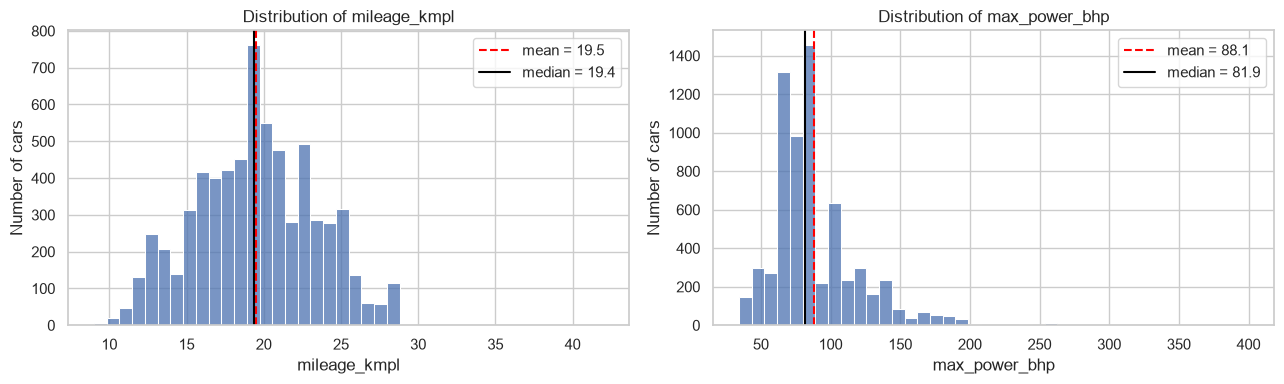

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["mileage_kmpl", "max_power_bhp"]):
    values = cars[col].dropna()
    sns.histplot(values, bins=40, ax=ax)
    ax.axvline(values.mean(), color="red", linestyle="--", label=f"mean = {values.mean():.1f}")
    ax.axvline(values.median(), color="black", label=f"median = {values.median():.1f}")
    ax.set(title=f"Distribution of {col}", xlabel=col, ylabel="Number of cars")
    ax.legend()
plt.tight_layout()
plt.show()

In [22]:
for col in ["mileage_kmpl", "max_power_bhp"]:
    print(f"{col}: mean={cars[col].mean():.2f}, median={cars[col].median():.2f}, skew={cars[col].skew():.2f}")

mileage_kmpl: mean=19.48, median=19.40, skew=0.03
max_power_bhp: mean=88.12, median=81.86, skew=1.71


**Decision.** `mileage_kmpl` is close to symmetric (skew 0.03; mean 19.48 vs median 19.40), so the mean and median would both work. `max_power_bhp` is clearly **right-skewed** (skew 1.71): a small number of high-power cars (up to 400 bhp) pull the mean (88.1) above the median (81.9). The median is the better simple imputation choice for power, and also for `engine_cc` (skew 1.2). For consistency and robustness, **the median is used for all three numeric columns**.

### **Task 3.6 – Apply `SimpleImputer`**

`SimpleImputer` separates two stages:
- **`fit`** learns the replacement statistic (here the median) and stores it in `statistics_`.
- **`transform`** applies the stored value.

`fit_transform()` does both in one call. The split matters for machine learning: you fit on the training data only, then transform both the training and test data with the *training* median. `fillna(df.median())` recomputes the median from whatever data it is given, which leaks information from the test set.

In [23]:
num_imputer = SimpleImputer(strategy="median")
num_imputer.fit(cars[num_cols])
print("Learned medians:", dict(zip(num_cols, num_imputer.statistics_)))

cars_clean = cars.copy()
cars_clean[num_cols] = num_imputer.transform(cars[num_cols])

# seats is discrete, so use the mode. scikit-learn needs a 2-D input, hence [["seats"]].
seat_imputer = SimpleImputer(strategy="most_frequent")
cars_clean[["seats"]] = seat_imputer.fit_transform(cars[["seats"]])

missing_report(cars_clean)

Learned medians: {'mileage_kmpl': np.float64(19.4), 'engine_cc': np.float64(1248.0), 'max_power_bhp': np.float64(81.86)}


,missing,percent
name,0,0.0
year,0,0.0
selling_price,0,0.0
km_driven,0,0.0
fuel,0,0.0
seller_type,0,0.0
transmission,0,0.0
owner,0,0.0
seats,0,0.0
mileage_kmpl,0,0.0


### **Task 3.7 – Validate the Cleaned Cars Dataset**

In [24]:
summary = pd.DataFrame({
    "before": [cars_before.shape, cars_before.isna().sum().sum(), cars_before.duplicated().sum()],
    "after": [cars_clean.shape, cars_clean.isna().sum().sum(), cars_clean.duplicated().sum()],
}, index=["shape", "missing cells", "duplicate rows"])
summary

,before,after
shape,"(8033, 12)","(6832, 12)"
missing cells,873,0
duplicate rows,1201,0


In [25]:
pd.concat({"before": cars_before[num_cols].describe(), "after": cars_clean[num_cols].describe()}, axis=1).round(2)

before                                after            \
      mileage_kmpl engine_cc max_power_bhp mileage_kmpl engine_cc   
count      7802.00   7819.00       7819.00      6832.00   6832.00   
mean         19.43   1463.09         91.94        19.48   1430.17   
std           3.90    504.66         35.77         3.85    488.25   
min           9.00    624.00         34.20         9.00    624.00   
25%          16.78   1197.00         69.00        16.96   1197.00   
50%          19.30   1248.00         82.40        19.40   1248.00   
75%          22.32   1582.00        102.00        22.32   1498.00   
max          42.00   3604.00        400.00        42.00   3604.00   

                     
      max_power_bhp  
count       6832.00  
mean          87.93  
std           31.30  
min           34.20  
25%           68.00  
50%           81.86  
75%           99.00  
max          400.00

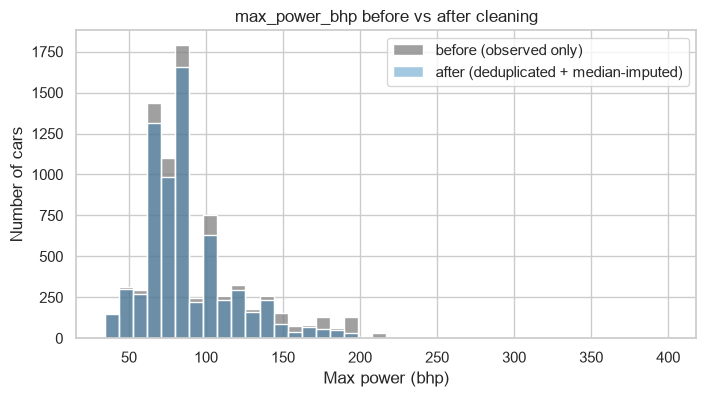

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(cars_before["max_power_bhp"].dropna(), bins=40, color="grey", label="before (observed only)", ax=ax)
sns.histplot(cars_clean["max_power_bhp"], bins=40, color="tab:blue", alpha=0.4, label="after (deduplicated + median-imputed)", ax=ax)
ax.set(title="max_power_bhp before vs after cleaning", xlabel="Max power (bhp)", ylabel="Number of cars")
ax.legend()
plt.show()

**Validation**

- **Shape** went from 8,033 to 6,832 rows (duplicates removed). **Missing cells** went from 873 to 0, and **duplicate rows** from 1,201 to 0.
- `mileage_kmpl` barely moved (mean 19.43 → 19.48, median 19.30 → 19.40).
- `max_power_bhp` fell (mean 91.94 → 87.93) and so did `engine_cc` (mean 1463 → 1430). The cause is the **deduplication**, not the imputation: the duplicated listings were disproportionately larger, more powerful cars, so they were inflating these averages.
- **The histogram keeps its shape after cleaning.** The bars are lower mainly because the duplicates are gone, most noticeably in the 150–200 bhp range. All 201 imputed values equal 81.86 bhp and land in the bin that was already the tallest (~80 bhp), so they create no new peak. With much heavier missingness, though, that single bin would grow out of proportion and distort the distribution.

## **Feature Engineering**

- **`power_per_litre`** = `max_power_bhp / (engine_cc / 1000)`. This dataset has no weight column, so engine size stands in for "how big is the car". The ratio shows how hard an engine is tuned: two 100 bhp cars behave differently with a 1.0 L and a 3.0 L engine.
- **Categorical features** (`fuel`, `transmission`, `seller_type`, `owner`) take the role that `Origin` plays in Auto MPG. Models need numbers, so each category becomes its own 0/1 column (one-hot encoding). `drop_first=True` drops one category per feature because it is implied: if `fuel_Petrol` is 0, the car is Diesel. Keeping it would make the columns perfectly redundant (the "dummy variable trap" for linear regression).
- **`name` is left out of the first model.** It has thousands of unique values, so one-hot encoding it would create thousands of near-empty columns.

In [27]:
cars_clean = add_power_per_litre(cars_clean)
print(cars_clean["power_per_litre"].describe().round(2))

# Always check the extremes of a new feature, because that is where bugs and oddities show up
cars_clean.nlargest(3, "power_per_litre")[["name", "engine_cc", "max_power_bhp", "power_per_litre"]]

count    6832.00
mean       62.71
std        12.17
min        21.31
25%        59.21
50%        64.83
75%        68.39
max       203.15
Name: power_per_litre, dtype: float64


,name,engine_cc,max_power_bhp,power_per_litre
167,Volvo XC90 T8 Excellence BSIV,1969.0,400.00,203.148807
1198,Ford Ecosport 1.0 Ecoboost Titanium Optional,999.0,123.37,123.493493
6351,Ford Ecosport 1.0 Ecoboost Titanium Optional,999.0,123.37,123.493493


In [28]:
cat_cols = ["fuel", "transmission", "seller_type", "owner"]
encoded_preview = pd.get_dummies(cars_clean[cat_cols], drop_first=True, dtype=int)
print(encoded_preview.columns.tolist())
encoded_preview.head(3)

['fuel_Petrol', 'transmission_Manual', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


,fuel_Petrol,transmission_Manual,seller_type_Individual,seller_type_Trustmark Dealer,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,0,1,1,0,0,0,0,0
1,0,1,1,0,0,1,0,0
2,1,1,1,0,0,0,0,1


The typical car produces about **65 bhp per litre** (median 64.83). The maximum, 203 bhp/L, is a Volvo XC90 T8: a plug-in hybrid whose combined power rating is listed against a 2.0 L engine. It is a legitimate car rather than a data error, and it shows why the extremes of a new feature are worth checking. The four categorical columns become **8 binary columns** after encoding.

## **Exploratory Data Analysis**

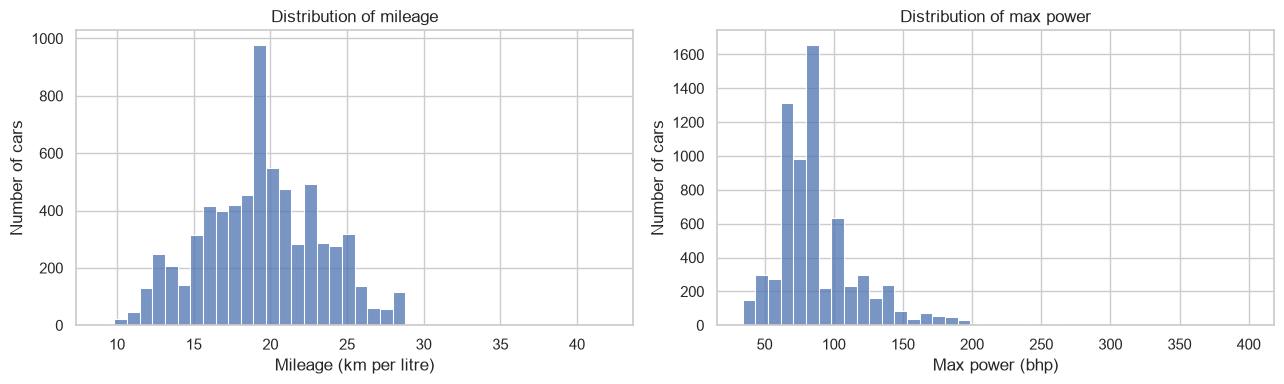

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(cars_clean["mileage_kmpl"], bins=40, ax=axes[0])
axes[0].set(title="Distribution of mileage", xlabel="Mileage (km per litre)", ylabel="Number of cars")
sns.histplot(cars_clean["max_power_bhp"], bins=40, ax=axes[1])
axes[1].set(title="Distribution of max power", xlabel="Max power (bhp)", ylabel="Number of cars")
plt.tight_layout()
plt.show()

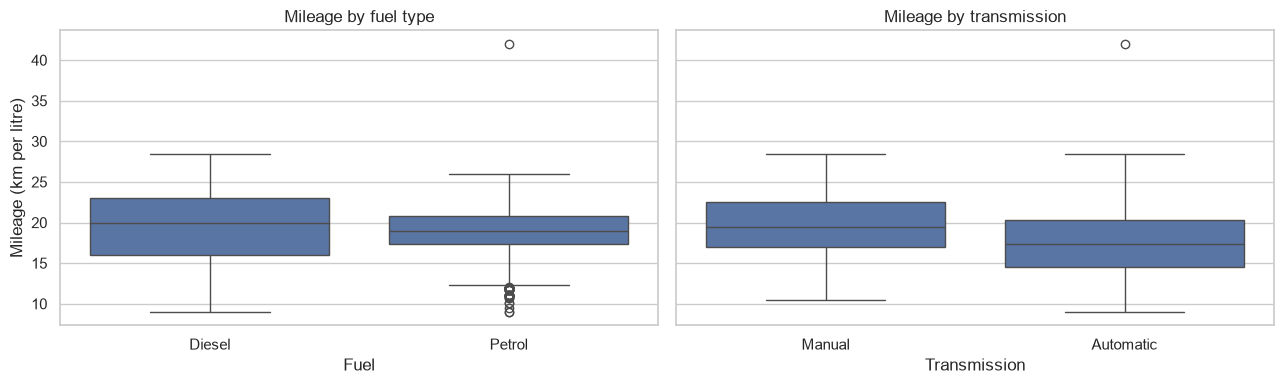

fuel
Diesel    20.0
Petrol    19.0
Name: mileage_kmpl, dtype: float64
transmission
Automatic    17.38
Manual       19.50
Name: mileage_kmpl, dtype: float64


In [30]:
# sharey=True puts both plots on the same mileage axis so they can be compared honestly
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sns.boxplot(data=cars_clean, x="fuel", y="mileage_kmpl", ax=axes[0])
axes[0].set(title="Mileage by fuel type", xlabel="Fuel", ylabel="Mileage (km per litre)")
sns.boxplot(data=cars_clean, x="transmission", y="mileage_kmpl", ax=axes[1])
axes[1].set(title="Mileage by transmission", xlabel="Transmission", ylabel="")
plt.tight_layout()
plt.show()

print(cars_clean.groupby("fuel")["mileage_kmpl"].median())
print(cars_clean.groupby("transmission")["mileage_kmpl"].median())

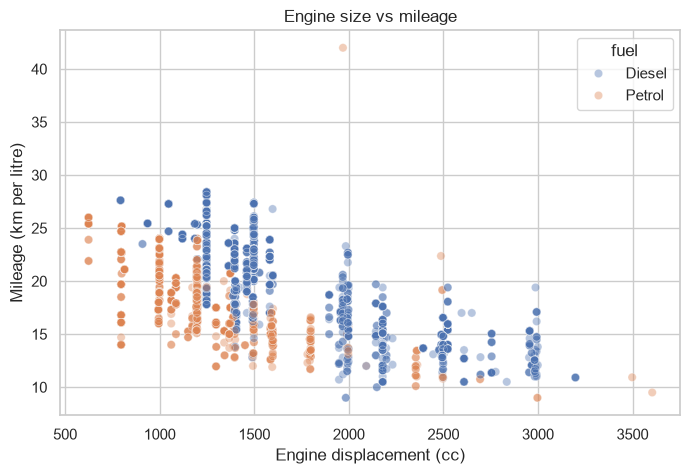

In [31]:
# alpha makes points semi-transparent, so dense regions show up darker
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=cars_clean, x="engine_cc", y="mileage_kmpl", hue="fuel", alpha=0.4, ax=ax)
ax.set(title="Engine size vs mileage", xlabel="Engine displacement (cc)", ylabel="Mileage (km per litre)")
plt.show()

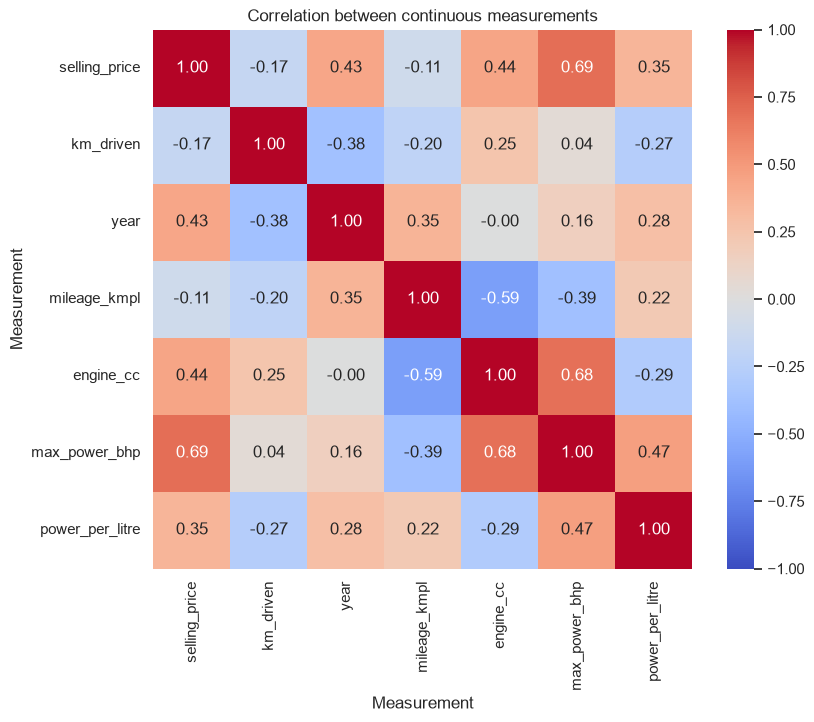

In [32]:
continuous = ["selling_price", "km_driven", "year", "mileage_kmpl", "engine_cc", "max_power_bhp", "power_per_litre"]
corr = cars_clean[continuous].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set(title="Correlation between continuous measurements", xlabel="Measurement", ylabel="Measurement")
plt.show()

**EDA observations**

- **Distributions.** Mileage is roughly bell-shaped, centred around 19–20 km/l. The unusually tall bar at about 19.4 km/l is partly the **216 imputed medians**, which is why the hypothesis test below uses observed values only. Max power is right-skewed: most cars fall between 60 and 120 bhp, with a long tail of premium vehicles.
- **Fuel type.** Diesel cars have a slightly higher median mileage (20.0 vs 19.0 km/l) and a much wider spread than petrol cars.
- **Transmission.** Manual cars are more efficient (median 19.5 vs 17.4 km/l). This is partly because automatics in this data tend to be larger, more powerful cars.
- **Engine size vs mileage.** There is a clear negative relationship (r = −0.59): bigger engines burn more fuel. The points form vertical stripes because manufacturers use a few standard engine sizes (about 1200, 1500 and 2000 cc). One petrol car sits far above the rest at **42 km/l**. It is the Volvo XC90 T8 plug-in hybrid (the same car that tops `power_per_litre`), whose official rating includes electric driving. It is a genuine car, but its mileage is not comparable with ordinary petrol cars.
- **Correlations.** Selling price tracks power most closely (r = 0.69). Engine size and power are strongly related (0.68), so a model using both carries some redundancy (multicollinearity). Newer cars have better mileage (year vs mileage r = 0.35) and fewer kilometres (−0.38). `power_per_litre` correlates *positively* with mileage (0.22), even though raw engine size correlates negatively: small, efficiently tuned engines are both frugal and punchy for their size.

## **Inferential Statistics – Diesel vs Petrol Mileage**

**The comparison is defined in advance**, before any test is run. Choosing a hypothesis after seeing which test comes out significant makes the p-value meaningless (p-hacking).

> **Question:** Do diesel and petrol cars in this dataset differ in fuel efficiency?
> **Variable:** `mileage_kmpl`, using **observed values only**. The deduplicated `cars` table is used, not `cars_clean`, because 216 imputed medians stacked at 19.4 would create a fake spike and understate the variance.
> **H₀:** mean mileage is the same for Diesel and Petrol cars. **H₁:** the means differ (two-sided).
> **Significance level:** α = 0.05.
> **Plan:** check normality per group (Q-Q plot and Shapiro–Wilk) and equal variances (Levene), then choose the two-sample test.

In [33]:
observed = cars.dropna(subset=["mileage_kmpl"])
diesel = observed.loc[observed["fuel"] == "Diesel", "mileage_kmpl"]
petrol = observed.loc[observed["fuel"] == "Petrol", "mileage_kmpl"]

pd.DataFrame({
    "n": [len(diesel), len(petrol)],
    "mean": [diesel.mean(), petrol.mean()],
    "median": [diesel.median(), petrol.median()],
    "std": [diesel.std(), petrol.std()],
}, index=["Diesel", "Petrol"]).round(2)

,n,mean,median,std
Diesel,3653,19.77,20.0,4.56
Petrol,2963,19.12,18.9,2.87


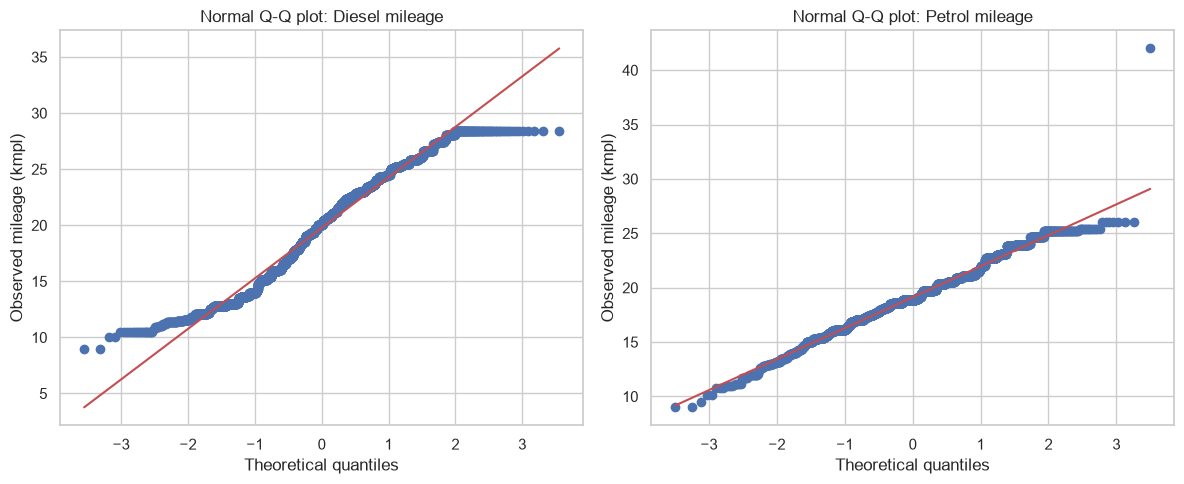

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, values) in zip(axes, [("Diesel", diesel), ("Petrol", petrol)]):
    stats.probplot(values, dist="norm", plot=ax)
    ax.set(title=f"Normal Q-Q plot: {label} mileage", xlabel="Theoretical quantiles", ylabel="Observed mileage (kmpl)")
plt.tight_layout()
plt.show()

In [35]:
for label, values in [("Diesel", diesel), ("Petrol", petrol)]:
    w, p = stats.shapiro(values)
    print(f"Shapiro-Wilk {label}: W = {w:.4f}, p = {p:.2e}")

lev = stats.levene(diesel, petrol)
print(f"Levene (equal variances): W = {lev.statistic:.1f}, p = {lev.pvalue:.2e}")

Shapiro-Wilk Diesel: W = 0.9719, p = 3.22e-26
Shapiro-Wilk Petrol: W = 0.9858, p = 1.13e-16
Levene (equal variances): W = 947.8, p = 1.25e-194


**Checking the assumptions**

- **Normality.** Shapiro–Wilk rejects normality for both groups (p < 0.001). However, W ≈ 0.97–0.99 is *very close* to 1. With thousands of observations, Shapiro–Wilk flags even trivial departures from normality, so the Q-Q plots matter more. **Petrol** follows the line closely across almost its whole range. The only clear departure is the single hybrid at 42 km/l in the top-right corner. **Diesel** follows the line through the middle but flattens into plateaus at both ends (around 10–11 km/l and 28.4 km/l). Its tails are *lighter* than a normal distribution's, because diesel mileage values are bounded: 85 unique listings share the 28.4 km/l maximum. Neither group is exactly normal, but neither is badly skewed.
- **Equal variances.** Levene's test strongly rejects equal variances: the diesel spread (std 4.56) is much larger than the petrol spread (2.87).

**Choice of test**

- The groups are independent, but the variances differ, so Student's t-test is ruled out.
- With n ≈ 3,000 per group, the **Central Limit Theorem** makes the *sampling distribution of the mean* approximately normal even though the raw data are not.
- The primary test is therefore **Welch's t-test** (`equal_var=False`). As a robustness check, the **Mann–Whitney U** test, which makes no normality assumption, is also run. If both agree, the conclusion does not depend on the normality assumption.

In [36]:
welch = stats.ttest_ind(diesel, petrol, equal_var=False)
print(f"Welch's t-test: t = {welch.statistic:.2f}, df = {welch.df:.0f}, p = {welch.pvalue:.2e}")

mwu = stats.mannwhitneyu(diesel, petrol, alternative="two-sided")
print(f"Mann-Whitney U: U = {mwu.statistic:.0f}, p = {mwu.pvalue:.2e}")

# Effect size: a significant result is not necessarily an important one
pooled_sd = np.sqrt(((len(diesel) - 1) * diesel.var() + (len(petrol) - 1) * petrol.var()) / (len(diesel) + len(petrol) - 2))
cohens_d = (diesel.mean() - petrol.mean()) / pooled_sd
print(f"Mean difference = {diesel.mean() - petrol.mean():.2f} kmpl, Cohen's d = {cohens_d:.2f}")

Welch's t-test: t = 6.97, df = 6246, p = 3.41e-12
Mann-Whitney U: U = 5981641, p = 1.64e-13
Mean difference = 0.64 kmpl, Cohen's d = 0.16


**Interpretation**

Both tests reject H₀ at α = 0.05: Welch's t = 6.97 (df ≈ 6,246, p ≈ 3.4 × 10⁻¹²) and Mann–Whitney U also gives p ≈ 1.6 × 10⁻¹³. Diesel cars in this dataset are **more fuel-efficient on average than petrol cars**.

However, the difference is **small in practical terms**: about **0.64 km/l** on means and 1.1 km/l on medians, with **Cohen's d = 0.16** (where 0.2 counts as "small"). The p-value is tiny because the sample is large, not because the effect is big. With about 6,600 cars, even a modest difference is detected with near certainty.

**Caveat.** This is observational data, so the test shows that the groups differ, not *why*. Diesel and petrol cars also differ in engine size, vehicle type and age, so fuel type alone should not be read as the cause.

## **Optional – Predicting Mileage with Regression**

**Goal:** predict `mileage_kmpl` from the car's other characteristics, compare the model against a simple baseline, and evaluate it on held-out data.

In [37]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

model_df = add_power_per_litre(cars.dropna(subset=["mileage_kmpl"]))

numeric_features = ["year", "km_driven", "engine_cc", "max_power_bhp", "power_per_litre", "seats"]
categorical_features = ["fuel", "transmission", "seller_type", "owner"]

X = model_df[numeric_features + categorical_features]
y = model_df["mileage_kmpl"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: (5292, 10), Test: (1324, 10)


In [38]:
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical_features),
])


def evaluate(name, regressor):
    pipe = Pipeline([("prep", clone(preprocess)), ("model", regressor)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    scores = {
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "R2": r2_score(y_test, pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, pred) * 100,
    }
    return scores, pipe, pred


In [39]:
baseline_scores, baseline_pipe, baseline_pred = evaluate("Baseline (predict mean)", DummyRegressor(strategy="mean"))
linreg_scores, linreg_pipe, linreg_pred = evaluate("Linear regression", LinearRegression())

pd.DataFrame([baseline_scores, linreg_scores]).set_index("model").round(3)


,MAE,RMSE,R2,MAPE (%)
model,,,,
Baseline (predict mean),3.234,4.016,-0.000,18.031
Linear regression,1.660,2.118,0.722,8.782


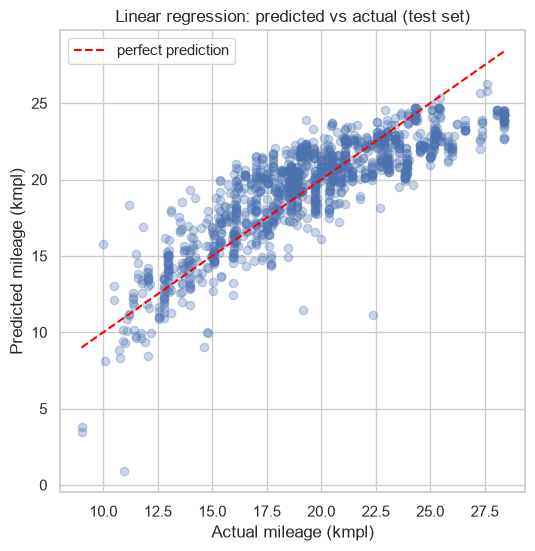

In [40]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, linreg_pred, alpha=0.3)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color="red", linestyle="--", label="perfect prediction")
ax.set(
    title="Linear regression: predicted vs actual (test set)",
    xlabel="Actual mileage (kmpl)",
    ylabel="Predicted mileage (kmpl)",
)
ax.legend()
plt.show()


**Model results**

- The **baseline** (always predicting the training mean) has MAE 3.23 km/l and R² ≈ 0, as expected, since R² measures improvement over the mean.
- **Linear regression** roughly **halves the error**: MAE 1.66 km/l, RMSE 2.12 km/l, R² 0.72. The features explain about 72% of the variation in mileage on cars the model never saw during training.
- **MAPE 8.8%:** a typical prediction is within about 9% of the true mileage, against 18.0% for the baseline. Regression has no "accuracy" in the classification sense (a continuous prediction is almost never exactly right), so R², MAE and MAPE together describe how close the predictions are.
- RMSE is only somewhat larger than MAE, so the model makes some larger misses but no extreme ones.
- In the predicted-vs-actual plot, most points follow the diagonal, with a pattern typical of linear regression: the model **under-predicts the most efficient cars** (actual 25–28 km/l are mostly predicted at 22–24) and tends to **over-predict thirsty cars**, pulling predictions toward the average. A few predictions are physically implausible (about 1–4 km/l for cars that actually achieve 9–11 km/l), which shows that a straight-line model can extrapolate badly for unusual cars.

**Why this evaluation is trustworthy:** duplicates were removed before splitting, the target was never imputed, and imputation and encoding were learned from the training set only inside the pipeline. No information from the test set leaked into training.

**Possible next steps:** a non-linear model such as a random forest, adding brand extracted from `name`, or cross-validation for a more stable estimate than a single split.


### **Task 3.8 – Cars Reflection**

**1. What were the main data-quality problems?**
- **Numbers stored as text.** `mileage`, `engine` and `max_power` had their units glued on (`"23.4 kmpl"`, `"1248 CC"`, `"74 bhp"`), so pandas read them as strings.
- **A hidden placeholder.** One `max_power` value was `" bhp"`, a unit with no number. pandas counted it as present even though it carried no information.
- **Mixed units.** 88 mileage values were in km/kg (CNG/LPG cars) rather than km/l.
- **Impossible values.** 17 cars had 0 km/l and 6 had 0 bhp.
- **Missing values.** About 3% of cars were missing their technical specs, and usually all of them at once.
- **Duplicates.** 1,201 exact duplicate listings, about 15% of the Diesel/Petrol rows.
- **An unusable column.** `torque` mixed units (Nm and kgm) and rpm ranges, so it was too inconsistent to use without heavy parsing.

**2. How many missing values did you find?**
In the raw file: `mileage` 221, `engine` 221, `max_power` 215 (216 once the `" bhp"` placeholder is counted), `torque` 222 and `seats` 221. After restricting to Diesel/Petrol cars and recoding impossible zeros as missing, there were **873 missing cells** across 8,033 rows. That is `mileage_kmpl` 231 (2.88%) plus `engine_cc`, `max_power_bhp` and `seats` at 214 each (2.66%). After deduplication, 819 missing cells remained across 6,832 rows.

**3. What happened when you dropped rows containing missing values?**
The data went from 6,832 to 6,616 rows: **216 cars (3.2%) were lost.** That is a modest loss, but the dropped rows are not a random sample. 201 of the 216 are listings missing *all* their specifications (the other 15 had an impossible 0 km/l mileage), so dropping them can bias the data if those listings differ systematically (for example, by coming from a particular kind of seller).

**4. Why might dropping entire columns be inappropriate?**
`dropna(axis=1)` removed `mileage_kmpl`, `engine_cc`, `max_power_bhp` and `seats`, which are the most informative features in the dataset, to avoid about 3% missingness. More than 97% of the valid values in those columns would be thrown away. Dropping a column only makes sense when most of it is missing or it is irrelevant.

**5. When is mean imputation reasonable?**
When the variable is roughly symmetric with no strong outliers and only a small share is missing, the mean is a fair "typical" value. `mileage_kmpl` is an example: skew 0.03, mean 19.48 vs median 19.40, so the two are almost interchangeable.

**6. When might median be safer than mean?**
When the distribution is skewed or has outliers, because the median is not pulled by extreme values. `max_power_bhp` is right-skewed (skew 1.71), and a few cars of up to 400 bhp drag the mean (88.12) well above the median (81.86). Filling with the mean would assign a typical car more power than it really has.

**7. Where would mode imputation be appropriate?**
For categorical or discrete variables, where an average is meaningless. `seats` was filled with its mode, 5, because a car cannot have 5.44 seats. Mode imputation would also suit `fuel` or `transmission` if those columns had missing values.

**8. How did `SimpleImputer` differ from manually calling `fillna()`?**
`SimpleImputer` separates **`fit`** (learn and store the statistic in `statistics_`) from **`transform`** (apply it). The learned medians (19.4 km/l, 1,248 cc, 81.86 bhp) can then be reused unchanged on new data. In machine learning this means fitting on the training set only and applying the *training* median to the test set, which avoids leakage. It also handles several columns in one step and plugs directly into a scikit-learn `Pipeline`. `fillna(df.median())` recomputes the statistic from whatever data it is given, and has to be written column by column.

**9. Did cleaning materially change the dataset statistics?**
For mileage, barely: the mean moved from 19.43 to 19.48 km/l. For power and engine size, yes. Mean power fell from 91.94 to 87.93 bhp and mean engine size from 1,463 to 1,430 cc. Comparing the strategies shows this came mostly from **removing duplicates**, which had over-represented larger, more powerful cars, rather than from imputation. Imputation's main side effect was a small reduction in standard deviation (for example, 31.75 → 31.30 bhp for power), because many identical values were added at the centre.

**10. Which cleaning decisions would you carry forward into an ML pipeline, and why?**
- **Deterministic fixes** (parsing units, recoding placeholders and zeros as missing, dropping `torque`) belong in reusable code, as already done in `src/car_dataset/`. They follow fixed rules and learn nothing from the data, so they are safe to apply before splitting.
- **Remove duplicates before the train/test split.** Otherwise the same car can appear in both sets and inflate the test score.
- **Keep the CNG/LPG exclusion**, or model those cars separately, because their mileage is in different units.
- **Median imputation (and mode imputation for `seats`) inside a `Pipeline` via `SimpleImputer`,** so the statistics are learned from training data only.
- **One-hot encode the categorical features inside the pipeline** with `OneHotEncoder(handle_unknown="ignore")`, so categories seen only in the test data don't cause errors.
- **Never impute the target.** Rows with missing `mileage_kmpl` are dropped before modelling, because the model would otherwise be trained to predict the median.

---
# **Answer to the Research Question**

> **Do diesel cars achieve significantly better fuel efficiency (mileage) than petrol cars, and how well can a car's listed characteristics (engine size, power, age, fuel type, transmission) predict its mileage?**

**Part 1: yes, diesel cars are significantly more efficient, but only slightly.**

| | Diesel | Petrol |
|---|---|---|
| Cars (observed mileage) | 3,653 | 2,963 |
| Mean mileage | 19.77 km/l | 19.12 km/l |
| Median mileage | 20.0 km/l | 18.9 km/l |

- Welch's t-test: t = 6.97, p ≈ 3.4 × 10⁻¹². Mann–Whitney U confirms it (p ≈ 1.6 × 10⁻¹³).
- **Effect size is small** (Cohen's d = 0.16; mean difference 0.64 km/l). The result is highly significant because the sample is large, not because the gap is big.

**Part 2: mileage is fairly predictable from the listing.**

| Model (held-out test set, 1,324 cars) | MAE | MAPE | R² |
|---|---|---|---|
| Baseline (always predict the mean) | 3.23 km/l | 18.0% | 0.00 |
| Linear regression | **1.66 km/l** | **8.8%** | **0.72** |

- The model explains about **72%** of the variation in mileage and **halves** the baseline's error. A typical prediction is within about 9% of the true value.
- **Engine size** is the strongest single factor (r = −0.59 with mileage: bigger engines, lower mileage). Newer cars are more efficient (r = 0.35), and manual cars beat automatics (median 19.5 vs 17.4 km/l).

**How we got here**

1. **Preparation:** units were stripped from text columns, 95 CNG/LPG cars (mileage in km/kg) were excluded, impossible zeros were recoded as missing, **1,201 duplicate listings** were removed, and the remaining ~3% of missing values were median/mode-imputed with `SimpleImputer`.
2. **Feature engineering:** `power_per_litre` was added, and the categorical columns were one-hot encoded.
3. **EDA:** showed diesel's slightly higher median mileage, the manual-vs-automatic gap, and the strong negative engine-size relationship.
4. **Inferential statistics:** Q-Q plots and Shapiro–Wilk showed the data are not exactly normal. With large samples (CLT), Welch's t-test is still valid, and Mann–Whitney U confirmed the result.
5. **Regression:** a pipeline that learns imputation and encoding from the training set only, compared against a mean baseline on held-out data.

**Limitations**

- This is **observational** data. It shows *association*, not *causation*. Diesel and petrol cars also differ in engine size, body type and age, so fuel type alone is not shown to *cause* the mileage difference.
- The mileage values appear to be **listed ratings** rather than measured real-world consumption (for example, 85 unique diesel listings, covering 14 different models, share exactly 28.4 km/l).
- The conclusions apply to **diesel and petrol cars only**, because CNG/LPG cars were excluded.
- The linear model **under-predicts the most efficient cars** and makes a few implausible predictions for unusual cars. A non-linear model (for example, a random forest) or adding the brand from `name` are natural next steps.